In [ ]:
!pip install numpy pandas matplotlib scipy


サンプル数: 60
平均: 1.0900 秒
標準偏差: 0.1399 秒
最小値: 0.8000 秒
最大値: 1.9000 秒


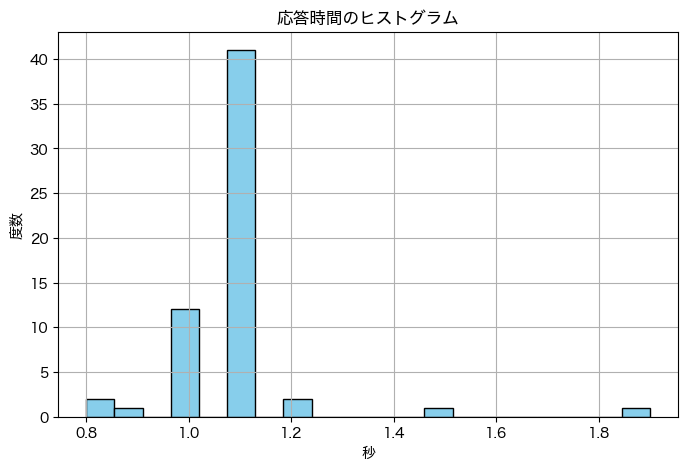

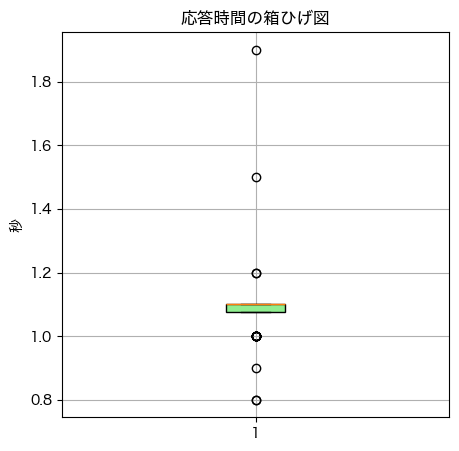

95%信頼区間: [1.0539 秒, 1.1261 秒]


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import scipy.stats as stats

# macOS のヒラギノフォント
matplotlib.rcParams['font.family'] = 'Hiragino Sans'

# ▼ ここにあなたの測定データを入力 ▼
data_str = '''
00:00.8
00:00.8
00:01.1
00:01.1
00:01.5
00:01.1
00:01.1
00:01.1
00:01.0
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.0
00:01.1
00:01.1
00:01.2
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.2
00:01.1
00:01.0
00:01.0
00:01.1
00:01.0
00:01.1
00:01.1
00:01.1
00:01.0
00:01.1
00:01.1
00:01.9
00:01.1
00:01.1
00:01.0
00:01.0
00:00.9
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.1
00:01.0
00:01.1
00:01.0
00:01.1
00:01.1
00:01.0
00:01.0
00:01.1
00:01.1
'''

# データをリストに変換
time_strings = [line.strip() for line in data_str.strip().split('\n') if line.strip()]

# "00:01.1" → 秒単位のfloat値に変換
def time_str_to_seconds(t):
    m, s = t.split(':')
    return float(m) * 60 + float(s)

data_sec = np.array([time_str_to_seconds(t) for t in time_strings])

# 基本統計量
mean_val = np.mean(data_sec)
std_val = np.std(data_sec, ddof=1)  # 標本標準偏差
min_val = np.min(data_sec)
max_val = np.max(data_sec)

print(f"サンプル数: {len(data_sec)}")
print(f"平均: {mean_val:.4f} 秒")
print(f"標準偏差: {std_val:.4f} 秒")
print(f"最小値: {min_val:.4f} 秒")
print(f"最大値: {max_val:.4f} 秒")

# ヒストグラム
plt.figure(figsize=(8,5))
plt.hist(data_sec, bins=20, color='skyblue', edgecolor='black')
plt.title('応答時間のヒストグラム')
plt.xlabel('秒')
plt.ylabel('度数')
plt.grid(True)
plt.show()

# 箱ひげ図
plt.figure(figsize=(5,5))
plt.boxplot(data_sec, vert=True, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('応答時間の箱ひげ図')
plt.ylabel('秒')
plt.grid(True)
plt.show()

# CSVに統計量を書き出し
stats_df = pd.DataFrame({
    '項目': ['平均', '標準偏差', '最小値', '最大値'],
    '値': [mean_val, std_val, min_val, max_val]
})



n = len(data_sec)
mean_val = np.mean(data_sec)
std_val = np.std(data_sec, ddof=1)

se = std_val / np.sqrt(n)
confidence = 0.95
t_value = stats.t.ppf((1 + confidence) / 2.0, df=n-1)

margin = t_value * se

ci_lower = mean_val - margin
ci_upper = mean_val + margin

print(f"95%信頼区間: [{ci_lower:.4f} 秒, {ci_upper:.4f} 秒]")


stats_df.to_csv('iot_switch_response_time_summary.csv', index=False, encoding='utf-8-sig')

# 全データをCSVに保存
all_data_df = pd.DataFrame({'応答時間[秒]': data_sec})
all_data_df.to_csv('iot_switch_response_time_all_data.csv', index=False, encoding='utf-8-sig')


サンプル数: 11
平均: 0.0835 秒
標準偏差: 0.0528 秒
最小値: 0.0280 秒
最大値: 0.2140 秒


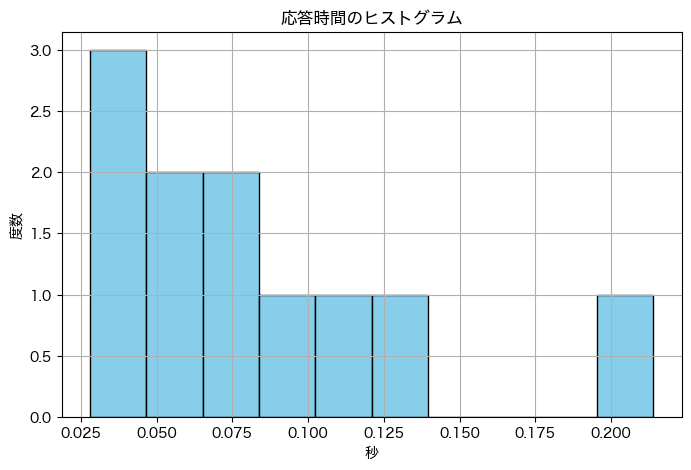

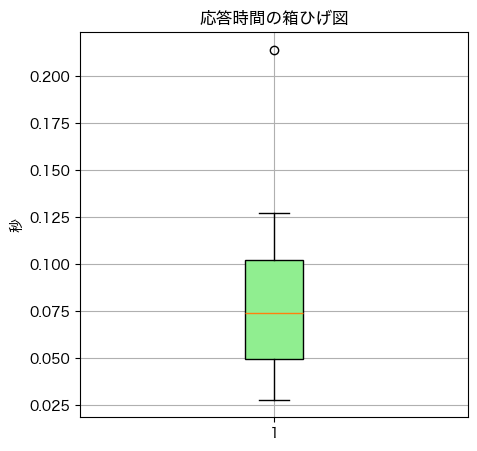

95%信頼区間: [0.0480 秒, 0.1189 秒]


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import scipy.stats as stats

# macOS のヒラギノフォント
matplotlib.rcParams['font.family'] = 'Hiragino Sans'

# ▼ ここにあなたの測定データを入力 ▼
data_str = '''
0.127
0.1
0.046
0.053
0.105
0.075
0.042
0.214
0.074
0.054
0.028
'''

# データをリストに変換
time_strings = [line.strip() for line in data_str.strip().split('\n') if line.strip()]

# 文字列を float に変換
data_sec = np.array([float(t) for t in time_strings])

# 基本統計量
mean_val = np.mean(data_sec)
std_val = np.std(data_sec, ddof=1)  # 標本標準偏差
min_val = np.min(data_sec)
max_val = np.max(data_sec)

print(f"サンプル数: {len(data_sec)}")
print(f"平均: {mean_val:.4f} 秒")
print(f"標準偏差: {std_val:.4f} 秒")
print(f"最小値: {min_val:.4f} 秒")
print(f"最大値: {max_val:.4f} 秒")

# ヒストグラム
plt.figure(figsize=(8,5))
plt.hist(data_sec, bins=10, color='skyblue', edgecolor='black')
plt.title('応答時間のヒストグラム')
plt.xlabel('秒')
plt.ylabel('度数')
plt.grid(True)
plt.show()

# 箱ひげ図
plt.figure(figsize=(5,5))
plt.boxplot(data_sec, vert=True, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('応答時間の箱ひげ図')
plt.ylabel('秒')
plt.grid(True)
plt.show()

# 信頼区間計算
n = len(data_sec)
se = std_val / np.sqrt(n)
confidence = 0.95
t_value = stats.t.ppf((1 + confidence) / 2.0, df=n-1)
margin = t_value * se
ci_lower = mean_val - margin
ci_upper = mean_val + margin

print(f"95%信頼区間: [{ci_lower:.4f} 秒, {ci_upper:.4f} 秒]")

# 統計量を CSV に書き出し
stats_df = pd.DataFrame({
    '項目': ['平均', '標準偏差', '最小値', '最大値', '95%信頼区間(下限)', '95%信頼区間(上限)'],
    '値': [mean_val, std_val, min_val, max_val, ci_lower, ci_upper]
})
stats_df.to_csv('UDPレイテンシ_summary.csv', index=False, encoding='utf-8-sig')

# 全データを CSV に保存
all_data_df = pd.DataFrame({'応答時間[秒]': data_sec})
all_data_df.to_csv('UDPレイテンシ_all_data.csv', index=False, encoding='utf-8-sig')


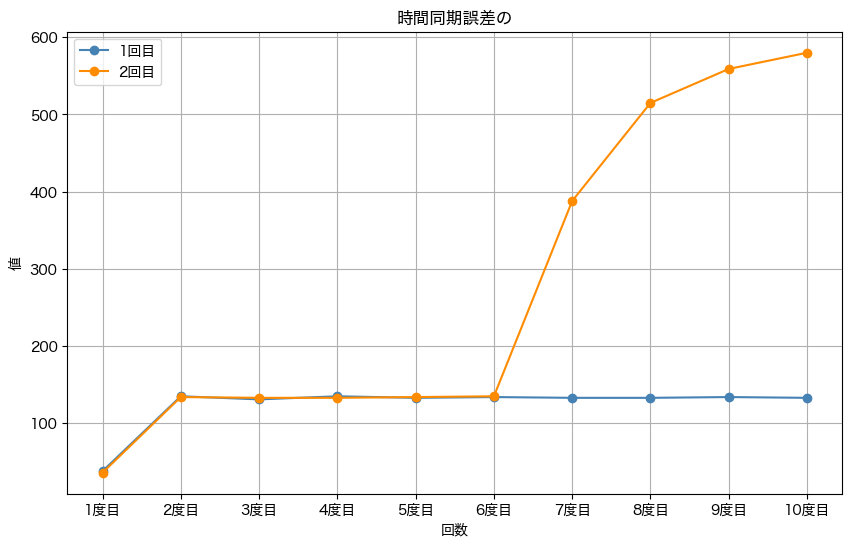

In [10]:
import matplotlib.pyplot as plt

# データ（あなたが送ってくれた値）
data_1st = [38, 135, 131, 135, 133, 134, 133, 133, 134, 133]
data_2nd = [36, 134, 133, 133, 134, 135, 388, 515, 559, 580]

x_labels = [f"{i+1}度目" for i in range(10)]

plt.figure(figsize=(10, 6))

# 1回目
plt.plot(x_labels, data_1st, marker='o', label='1回目', color='steelblue')

# 2回目
plt.plot(x_labels, data_2nd, marker='o', label='2回目', color='darkorange')

plt.title("時間同期誤差の")
plt.xlabel("回数")
plt.ylabel("値")
plt.legend()
plt.grid(True)

plt.show()
